# Assignment 1 — Working with Open Data

In this assignment you take a **real, public dataset**, ask questions of it, answer them, and document your work so that someone else could reproduce it.

**A few things to know before you start:**
- This course is about **data, not code.** The point of A1 is the analytical questions and what the numbers tell you about how people behave — *not* whether you remember Python syntax.
- You can do the analysis **in Python here, or in Google Sheets.** Every question below works either way. Pick whatever lets you think about the data instead of fighting the tool.
- You may use an **AI assistant** (ChatGPT, Claude, …) to help you write code — with rules. See *A note on using AI* at the bottom before you do.

**What you'll turn in** (committed to your `hcde-410` repo):
1. This notebook, with your answers filled in.
2. A short **README.md** describing your work.
3. A **LICENSE** file, and a note about the dataset's own license.

Your commit history is part of the record — commit as you go.

## Part 0 — Get the data

The data comes from [data.seattle.gov](https://data.seattle.gov/), the City of Seattle's open-data portal. We'll use the [Burke-Gilman Trail counter north of NE 70th St](https://data.seattle.gov/Transportation/Burke-Gilman-Trail-north-of-NE-70th-St-Bicycle-and/2z5v-ecg8), which records **bike and pedestrian traffic, by hour, by direction**.

We'll pull the data straight from the city's API rather than downloading a file by hand. That's a small reproducibility win: anyone who runs this notebook gets the same data the same way, and it's written down exactly where it came from.

In [2]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# The dataset's API endpoint, and a query for one year of data (2019).
# You can paste the full URL into a browser to preview the raw data.
api_endpoint = "https://data.seattle.gov/resource/2z5v-ecg8.json?"
api_parameters = "$limit=50000&$where=date > '2019-01-01T00:00:00' AND date < '2020-01-01T00:00:00'"

response = requests.get(api_endpoint + api_parameters)
raw_data = response.json()
print("Downloaded", len(raw_data), "hourly records.")
# If this cell fails (e.g. the API is down), see the note below the next cell.

Downloaded 8759 hourly records.


Now load it into a **pandas DataFrame** — a table, like a spreadsheet you can compute with.

In [4]:
df = pd.DataFrame(raw_data)
df.head()

,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south
0,2019-01-01T01:00:00.000,2,1,0,1,0
1,2019-01-01T02:00:00.000,1,0,0,0,1
2,2019-01-01T03:00:00.000,0,0,0,0,0
3,2019-01-01T04:00:00.000,1,0,0,1,0
4,2019-01-01T05:00:00.000,1,0,0,1,0


### Quick sanity checks

Whenever you work with data **you didn't create**, check that it means what you think before you analyze it. Two things need fixing here:
- the counts arrive as **text**, so we convert them to numbers;
- the `date` is a string, so we convert it to a real **datetime** and pull out the hour and weekday.

We'll also add tidy `bikes` and `peds` columns (north + south).

In [5]:
# convert the count columns from text to numbers
count_cols = ["bike_north", "bike_south", "ped_north", "ped_south", "bgt_north_of_ne_70th_total"]
df[count_cols] = df[count_cols].apply(pd.to_numeric, errors="coerce")

# convert the date string to a real datetime, and derive hour + weekday
df["date"] = pd.to_datetime(df["date"])
df["hour"] = df["date"].dt.hour
df["weekday"] = df["date"].dt.day_name()

# combined bike and pedestrian counts
df["bikes"] = df["bike_north"] + df["bike_south"]
df["peds"]  = df["ped_north"] + df["ped_south"]

df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8759 entries, 0 to 8758
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   date                        8759 non-null   datetime64[ns]
 1   bgt_north_of_ne_70th_total  8759 non-null   int64         
 2   ped_south                   8759 non-null   int64         
 3   ped_north                   8759 non-null   int64         
 4   bike_north                  8759 non-null   int64         
 5   bike_south                  8759 non-null   int64         
 6   hour                        8759 non-null   int32         
 7   weekday                     8759 non-null   object        
 8   bikes                       8759 non-null   int64         
 9   peds                        8759 non-null   int64         
dtypes: datetime64[ns](1), int32(1), int64(7), object(1)
memory usage: 650.2+ KB


,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south,hour,bikes,peds
count,8759,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000
mean,2019-07-02 12:00:00,58.423564,8.047380,8.363169,19.875671,22.137344,11.501313,42.013015,16.410549
min,2019-01-01 01:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2019-04-02 06:30:00,2.000000,0.000000,0.000000,0.000000,1.000000,6.000000,1.000000,0.000000
50%,2019-07-02 12:00:00,33.000000,5.000000,6.000000,9.000000,8.000000,12.000000,20.000000,11.000000
75%,2019-10-01 17:30:00,91.000000,13.000000,14.000000,31.000000,30.000000,17.500000,64.000000,27.000000
max,2019-12-31 23:00:00,1764.000000,1324.000000,782.000000,199.000000,961.000000,23.000000,1039.000000,1752.000000
std,NaN,73.656910,16.882468,13.164217,26.299728,34.080707,6.921886,56.534598,27.675776


**Look at what `describe()` tells you.** Are there hours with 0 traffic? Any missing values (a sensor can go offline)? Note anything odd — you'll want to mention data limitations later.

**No-code option:** run the next cell to save the cleaned data as a CSV, then open it in Google Sheets and do your analysis there. If you go this route, title your sheet **"A1 — [your name]"**, share it so anyone with the link can view, and paste the link into your written answers.

In [ ]:
df.to_csv("bg_hourly_2019.csv", index=False)
print("Saved bg_hourly_2019.csv — a row per hour of 2019.")

## Part 1 — One worked example: when do cyclists ride?

Here is the whole technique, **once**, so you can see the pattern. After this, the questions are yours.

The move is always the same: **group → summarize → plot → interpret.** In pandas that's a couple of lines (no loops needed).

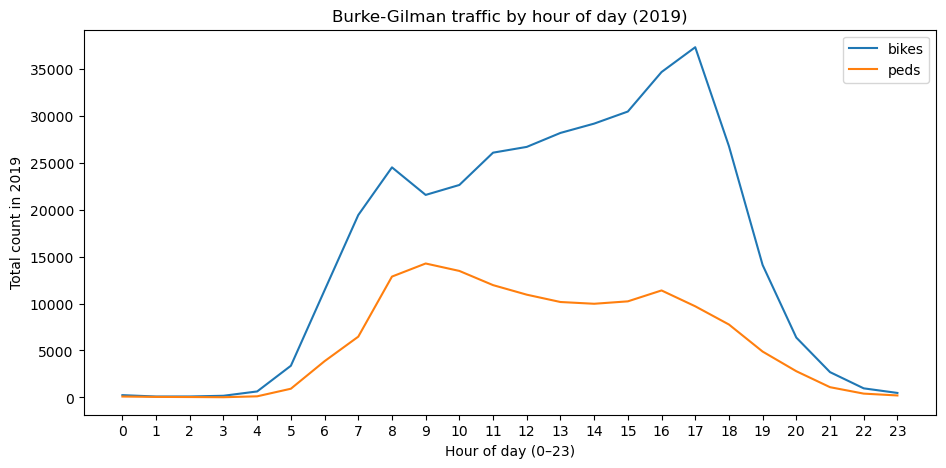

In [6]:
# group every row by its hour of day, and sum bikes and peds within each hour
by_hour = df.groupby("hour")[["bikes", "peds"]].sum()

by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

**Now read the plot — this is the actual work.** What does the shape tell you? Do you see one peak or two? What might a double peak mean about *why* people are on the trail? That interpretation — turning a shape into a claim about human behavior — is what every question below is really asking for.

## Part 2 — Your analysis

Answer each question below. For every one:
1. **Show how you got there** — a pandas cell here, or (no-code) a link to your Google Sheet in the answer.
2. **Interpret it in 2–4 sentences** — what does this say about how people actually use the trail? The interpretation is the point, not the number.

There isn't a single right answer to most of these. Making a reasonable choice and *defending* it is the skill.

**Q1. When is the trail busiest, and when is it quietest?**
Decide what *busy* means to you first — a single hour? a stretch of the day? bikes and peds together, or separately? — and say why you chose that.

Busiest Hour: 17
Mean number of bikes and peds combined: 128.75890410958903


Quietest Hour: 2
Mean number of bikes and peds combined: 0.40273972602739727


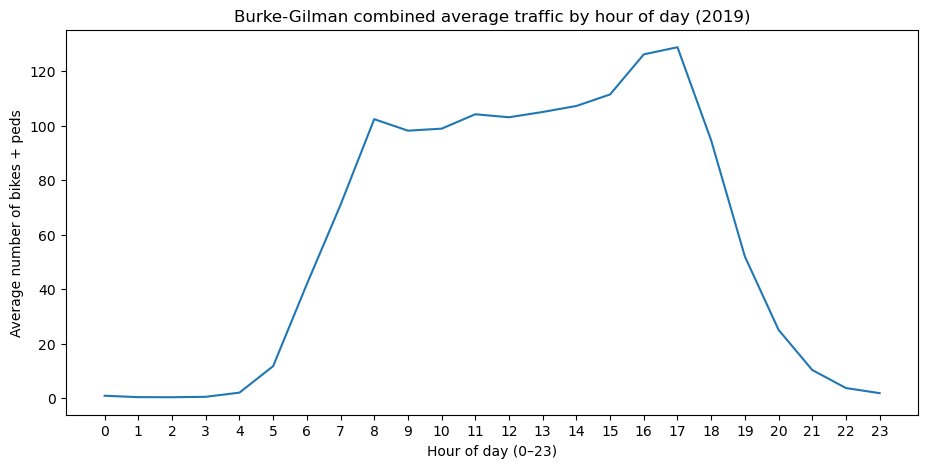

In [7]:
# Your code for Q1 (or put a Google Sheets link in your written answer below)

# Redefine by_hour to find the mean bikes and peds within each hour instead of sum
by_hour_mean = df.groupby("hour")[["bikes", "peds"]].mean()

# Total the mean number of bikes and peds within each hour
total_by_hour = by_hour_mean["bikes"] + by_hour_mean["peds"]

# Find the hour with the highest mean of bikes and peds (Busiest Hour)
busiest_hour = total_by_hour.idxmax()
print("Busiest Hour:", busiest_hour)
print("Mean number of bikes and peds combined:", total_by_hour.max())

print("\n")

# Find the hour with the lowest mean of bikes and peds (Quietest Hour)
quietest_hour = total_by_hour.idxmin()
print("Quietest Hour:", quietest_hour)
print("Mean number of bikes and peds combined:", total_by_hour.min())


total_by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman combined average traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Average number of bikes + peds")
plt.xticks(range(0, 24))
plt.show()

**Your Q1 answer:**

*I defined busy by the mean number of bikes and peds combined at each hour. I felt including both bikes and peds in the total gave the best representation of how busy the trail is at a given hour, since both user groups share the trail. The trail was busiest at 5 PM with an average of 129 bikes and peds combined, compared to less than 1 (0.40) bikes/peds combined at the quiestest hour, which was 2 AM. It appears the trail is busiest near the late afternoon/evening and much quieter overnight.*

**Q3 AI Use Statement:**

*I used ChatGPT to learn how to find the max and min in a pandas series and identify the index it occurs. This is the prompt I used:*

**Prompt 1:** *What is the syntax/function to find the min and max of a list of numbers and the index it occurs in Python, pandas*

**Output:** *If you have a pandas Series:*
*series.max()*
*series.idxmax()*
*max() → gives the maximum value*
*dxmax() → gives the index where the maximum occurs*

I then edited the output to align with the name of my series.

**Q2. Do cyclists and pedestrians use the trail at different times of day?**
Compare their hourly patterns. If they differ, what might explain it?

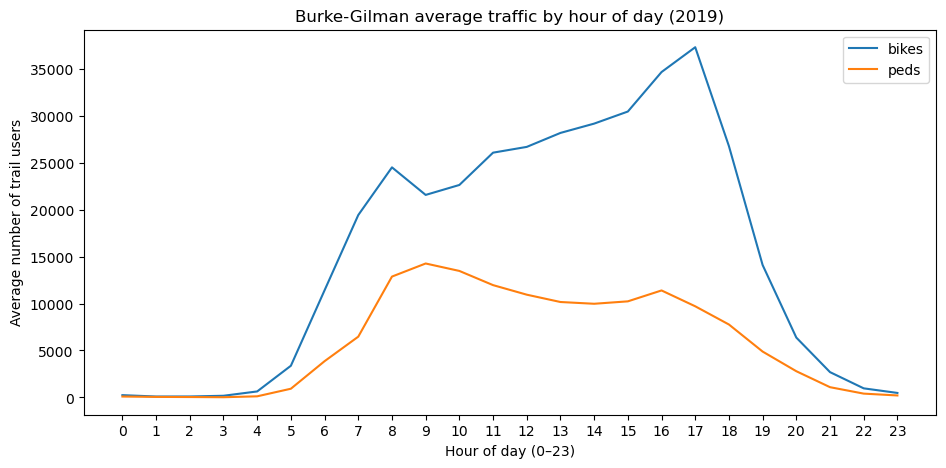

In [8]:
# Your code for Q2

# Reuse by_hour_mean to find the mean trail use of bikes versus peds by hour
by_hour_mean = df.groupby("hour")[["bikes", "peds"]].mean()

# Plot average traffic by hour for bikes and peds
by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman average traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Average number of trail users")
plt.xticks(range(0, 24))
plt.show()


**Your Q2 answer:**

*Yes, it does appear cyclists and pedestrians use the trail at different times of day. There are two notable spikes in bike use, first a morning high point at 8 AM and then a strong rise till 5 PM where it peaks for the whole day. In contrast, pedestrian use peaks in the morning around 9 AM and mostly declines to the end of the day. A possible explanation for these patterns is a good portion of cyclists mainly use the trail to commute (8 AM and 5 PM peaks), whereas pedestrians just use the trail more recreationally throughout the morning/day. Though, in addition to commuter cyclists, increased presence of recreational cyclists may be contributing to the afternoon rise of bikes till 5 PM.*

**Q3. Commuting or recreation?**
Is there evidence people use the Burke-Gilman to *commute*, not just for fun? Compare **weekdays vs. weekends** (we made a `weekday` column for you), and maybe morning vs. evening. Define what a "commuting pattern" would look like in the data, then say whether you see it.

*Hint: `df.groupby("weekday")[["bikes","peds"]].sum()` gets you started. Weekends and weekdays will look different if commuting is real.*

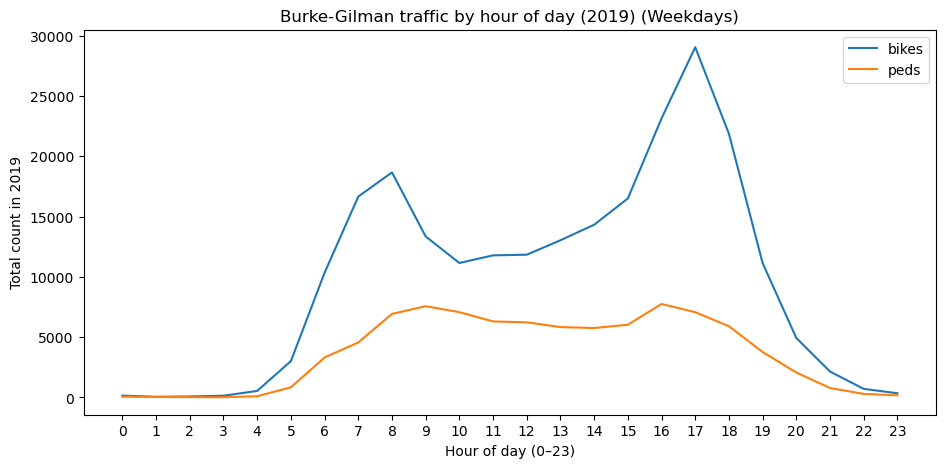

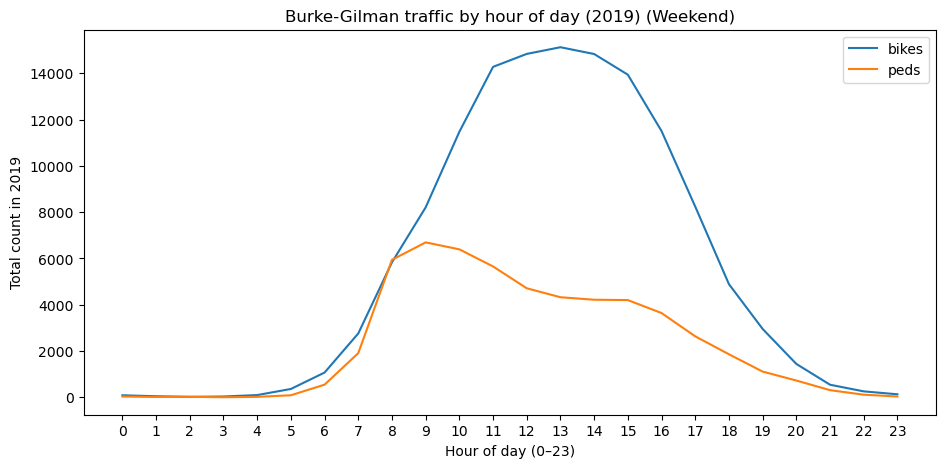

In [9]:
# Your code for Q3

# Group every row by its day of the week, and sum bikes and peds within each day
by_weekday = df.groupby("weekday")[["bikes", "peds"]].sum()

# Separate the days into weekdays and weekend
df["day_type"] = df["weekday"].apply(
    lambda day: "Weekend" if day in ["Saturday", "Sunday"] else "Weekday" 
)

by_hour_day_type = df.groupby(["day_type", "hour"])[["bikes", "peds"]].sum()

# Weekday hourly traffic plot
by_hour_day_type.loc["Weekday"].plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019) (Weekdays)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

# Weekend hourly traffic plot
by_hour_day_type.loc["Weekend"].plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019) (Weekend)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

**Your Q3 answer:**

*A commuting pattern would mostly mirror the standard 9 - 5 work schedule, with distinct peaks in the morning and afternoon on weekdays (especially among cyclists). This pattern is seen in the weekday data as there is a morning peak around 8 AM and afternoon peak at 5 PM for cyclists. Compare that to a bell-shaped pattern (1 PM peak) for bike use in the weekend data, which suggest more recreational use throughout the day. Thus, there is evidence that people do use the Burke-Gilman to commute.*

**Q3 AI Use Statement:**

*I used ChatGPT to help me write code to separate trail use data by weekdays versus weekends. I also used it to help me understand how to select a specific row from a DataFrame table to help create my two plots. These are the prompts I used:*

**Prompt 1:** *I have this piece of code which groups rows by day of the week and sums up the bike and pedestrian counts by the day: df.groupby("weekday")[["bikes","peds"]].sum(). How do I further separate it so Saturday and Sunday are put into a weekend group?*

**Output:** *You can create a new column called day_type that groups each day as either "Weekday" or "Weekend". Use .apply() with a lambda function to check whether the day is Saturday or Sunday.
df["day_type"] = df["weekday"].apply(    
    lambda day: "Weekend" if day in ["Saturday", "Sunday"] else "Weekday"
)*

I did not edit the output and used it directly in my code


**Prompt 2:** *Is there a way/what is the syntax to select a specific row from a DataFrame table?*

**Output:** *In pandas, you can use .loc[] to select a specific row from a DataFrame using its label.*

I applied this to separate my plots into .loc["Weekday"] and .lock["Weekend"].


**Q4. Direction and flow.**
The counter records **north vs. south** separately. Are mornings mostly one direction and evenings the other? What would that tell you about who's using the trail and where they're heading?

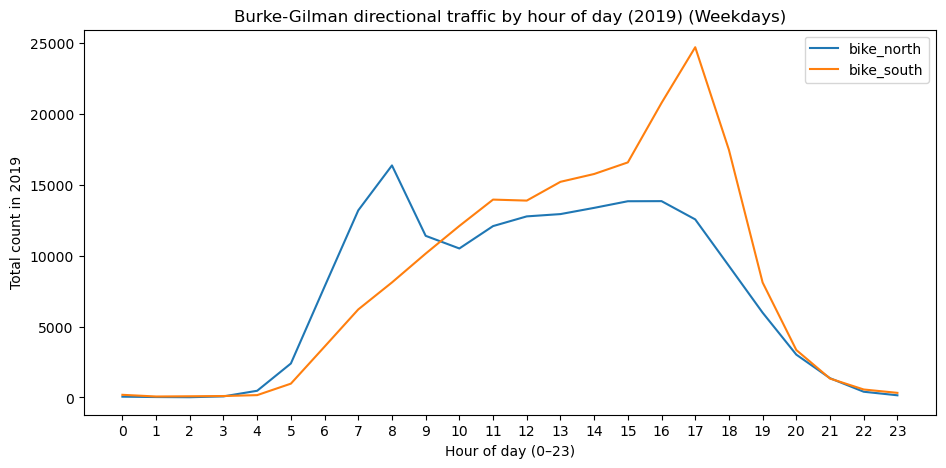

In [10]:
# Your code for Q4

by_hour_direction = df.groupby("hour")[["bike_north", "bike_south"]].sum()

by_hour_direction.plot(figsize=(11, 5))
plt.title("Burke-Gilman directional traffic by hour of day (2019) (Weekdays)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()


**Your Q4 answer:**

*(write here)*

## Part 3 — Make it reproducible

Good data work can be picked up and re-run by someone else. Two short deliverables:

**1. A `README.md`** in your `A1` folder. Use this template:

```
# A1 — Working with Open Data

**Dataset:** Burke-Gilman Trail counter north of NE 70th St
**Source:** https://data.seattle.gov/Transportation/.../2z5v-ecg8  (pulled YYYY-MM-DD)
**License / terms of use:** <find it on the dataset's page and note it here>

## Questions I asked
- ...

## How to re-run
Open `A1.ipynb` and run all cells (needs `requests`, `pandas`, `matplotlib`).
```

**2. A `LICENSE`** — keep the license file in this folder, and in your README **note the dataset's own license or terms of use** (open datasets almost always have one; find it on the dataset's page). Using open data responsibly means knowing what you're allowed to do with it — that's part of the assignment, not an afterthought.

### One more thing: read the data critically

In 3–4 sentences, name **one limitation or bias** in this dataset and how it could mislead someone who trusted it uncritically.

*(A sensor counts bodies, not intentions. It's one location on a long trail. Some hours may be missing when the counter was offline. A tandem bike counts once. What else?)* This is a warm-up for A2, where finding bias in data is the whole assignment.

**Your answer:**

*(write here)*

## Optional — going further

If you want to push further (not required for full credit):
- Which **day of the week** is busiest? Is it the same for bikes and pedestrians?
- Has the trail gotten **busier over time**? (the data goes back to 2014 — change the year in the query)
- Do fewer people ride when it's **cold or wet**? (join with a Seattle [weather dataset](https://data.seattle.gov/))
- Compare with another counter — the [Fremont Bridge](https://data.seattle.gov/Transportation/Fremont-Bridge-Bicycle-Counter/65db-xm6k) or the [MTS Trail](https://data.seattle.gov/Transportation/MTS-Trail-west-of-I-90-Bridge-Bicycle-and-Pedestri/u38e-ybnc).

## A note on using AI

You may use an LLM (ChatGPT, Claude, …) to help you write code or make a plot. Treat it as a **tool you supervise, not an author you trust**:
- paste the **prompt** you used into a Markdown cell,
- **run** the output and check it against what you expected,
- note **what you changed and why**.

Here, AI is your assistant. In **A3** it becomes your subject of study. Code that runs but that you can't explain won't earn credit — the point is that *you* can ask a question of data and defend the answer.